# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import FiveBillionPixelsDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 146


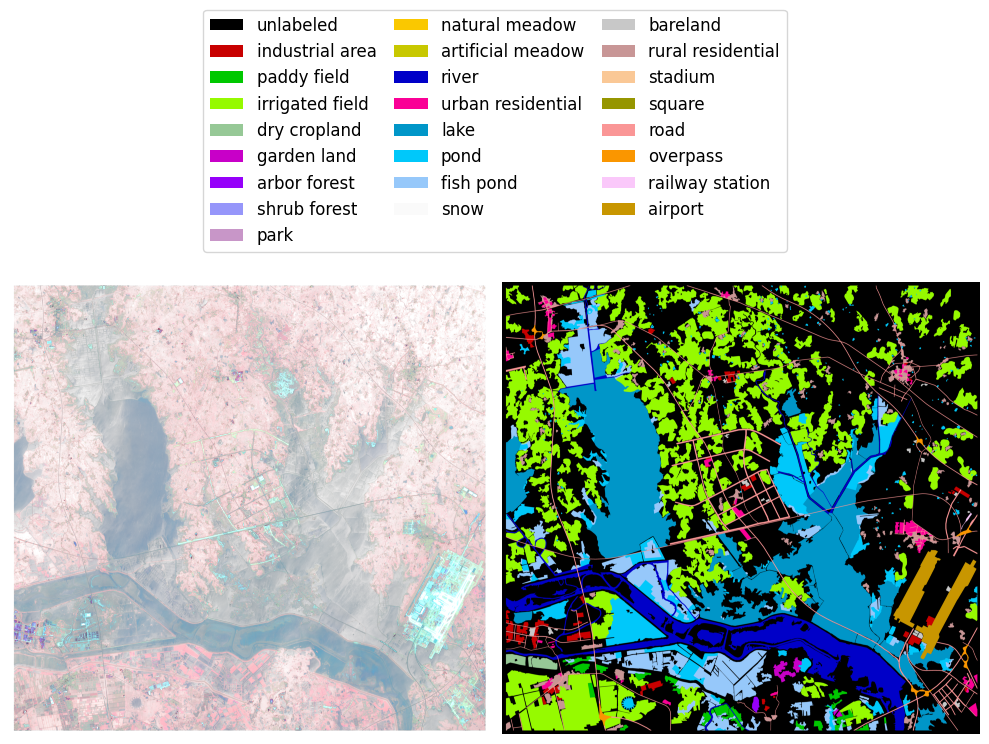

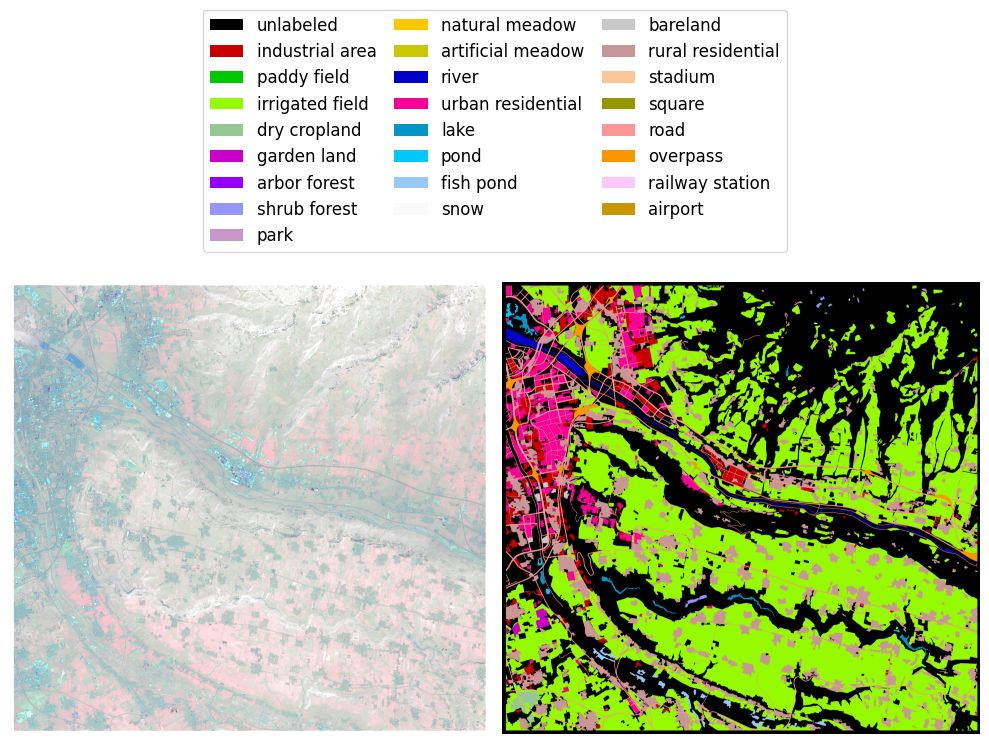

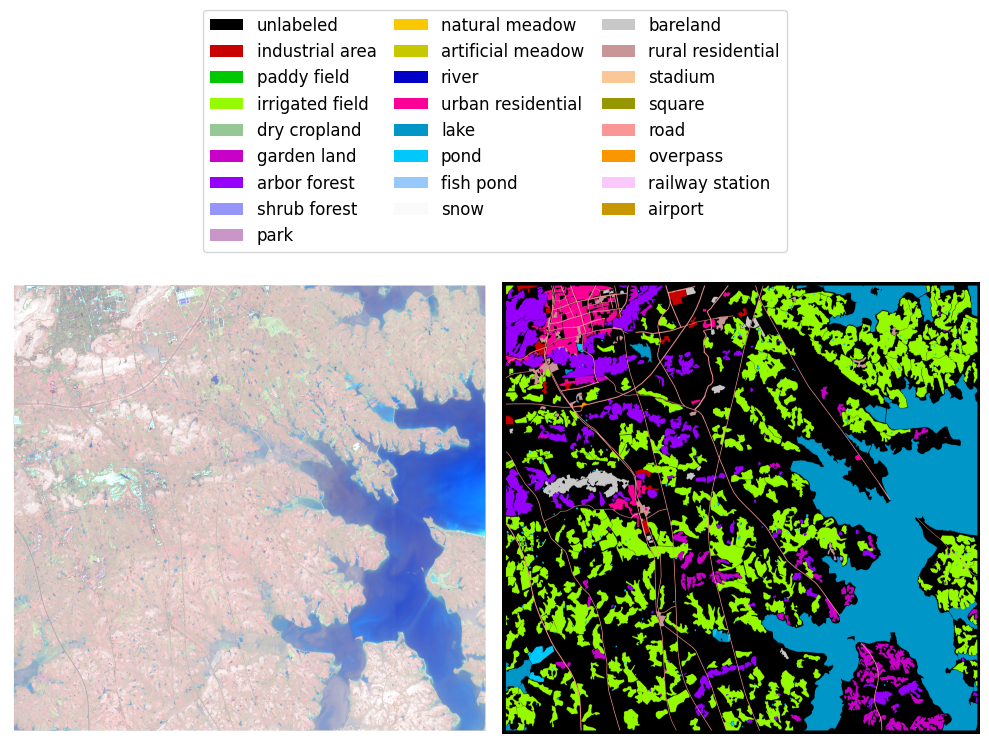

In [ ]:
dataset_config = {
    "data_dir": "./data/five_billion_pixels",
    "selection":"all"
}
dataset = FiveBillionPixelsDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(50);
dataset.show_image(100);

In [18]:
dataset.data_distribution_table()

,Number of pixels
unlabeled,2.427419e+09
industrial area,1.781077e+08
paddy field,1.212955e+08
irrigated field,1.812987e+09
dry cropland,3.258127e+08
garden land,4.582554e+07
arbor forest,4.048811e+08
shrub forest,1.902371e+08
park,2.920216e+06
natural meadow,8.618639e+07


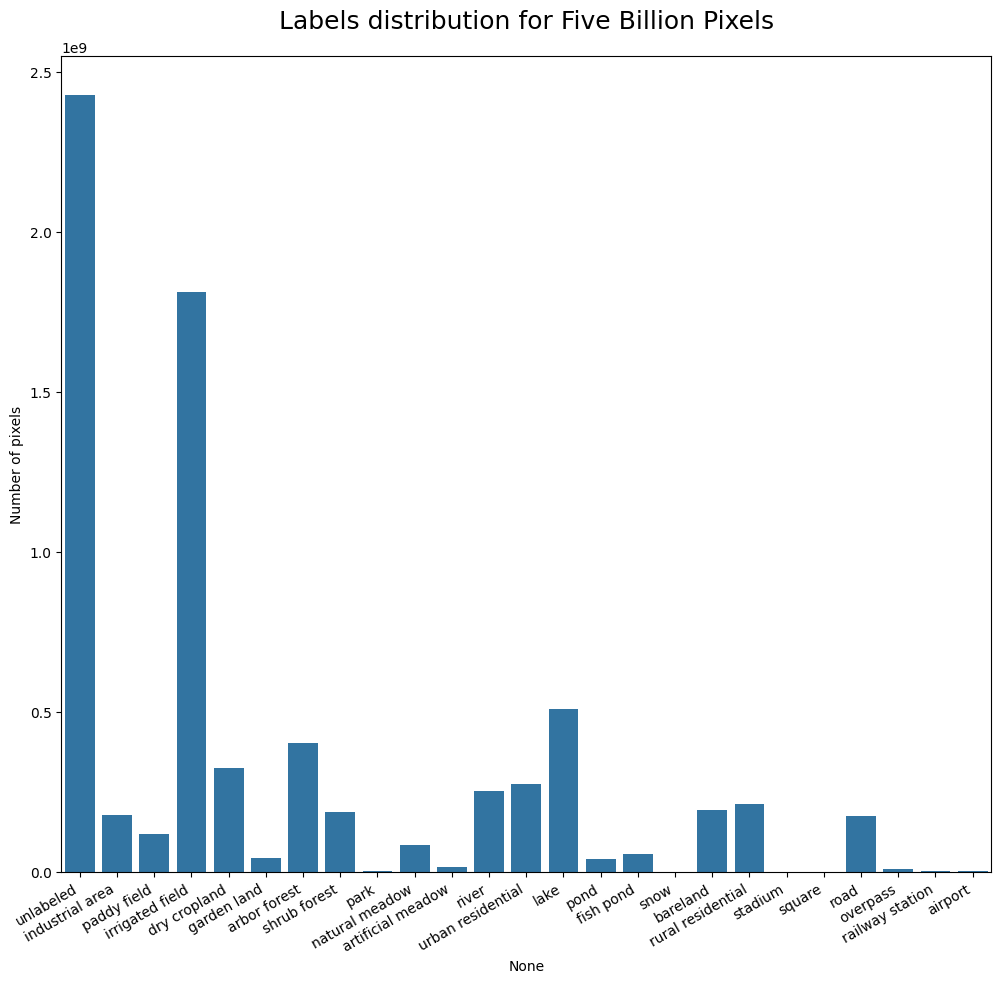

In [19]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 6,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/five_billion_pixels",
    "csv_file": "./data/five_billion_pixels/train.csv",
    "selection":"rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = FiveBillionPixelsDataset(train_dataset_config)
len(train_dataset)

118

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/five_billion_pixels"
model_config = {
    "num_classes": 25, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [42]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-13 13:41:07,157 INFO Starting training.
training: 100%|██████████| 20/20 [06:56<00:00, 20.81s/it]
2025-03-13 13:48:03,400 INFO epoch: 1, time: 416, loss:  0.91635
testing on train set: 100%|██████████| 20/20 [06:47<00:00, 20.38s/it]
2025-03-13 13:54:52,695 INFO IOU:0.03517985687975786, IOU mean:0.03263592132619294, IOU per Class:[1.29460544e-01 4.86280437e-03 9.25020909e-03 1.58640284e-01
 2.21553670e-01 1.47901856e-03 3.41669438e-02 1.53002939e-02
 9.41005514e-05 0.00000000e+00 2.00896194e-03 4.86894401e-02
 1.88629762e-02 1.23934386e-01 0.00000000e+00 2.43042954e-03
 0.00000000e+00 3.72315152e-02 7.26816804e-03 5.39674727e-06
 1.57077603e-06 4.82708574e-06 2.12542990e-04 5.75630398e-05
 3.82386396e-04]
training: 100%|██████████| 20/20 [06:48<00:00, 20.43s/it]
2025-03-13 14:01:41,246 INFO epoch: 2, time: 409, loss:  0.90209
testing on train set: 100%|██████████| 20/20 [06:58<00:00, 20.95s/it]
2025-03-13 14:08:40,232 INFO IOU:0.062389945031093234, IOU mean:0.03221157472193525, 

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/five_billion_pixels",
    "csv_file": "./data/five_billion_pixels/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = FiveBillionPixelsDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/five_billion_pixels/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

14


2025-03-13 16:00:23,364 INFO Loading checkpoint /home/dragik/data/FAIR_EO/five_billion_pixels/checkpoint.pth.tar
2025-03-13 16:00:23,820 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/five_billion_pixels/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 4/4 [00:55<00:00, 13.95s/it]


[{'IOU': 0.1459931256092044,
  'IOU mean': 0.04321771166158747,
  'IOU per Class': array([0.14117918, 0.        , 0.        , 0.13953548, 0.        ,
         0.        , 0.16949153, 0.        , 0.        , 0.        ,
         0.        , 0.39105604, 0.02306929, 0.21611127, 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ])}]

## Predictions

2025-03-14 08:04:27,433 INFO Loading checkpoint /home/dragik/data/FAIR_EO/five_billion_pixels/checkpoint.pth.tar
2025-03-14 08:04:27,698 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/five_billion_pixels/checkpoint.pth.tar at epoch 11


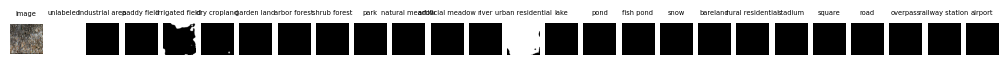

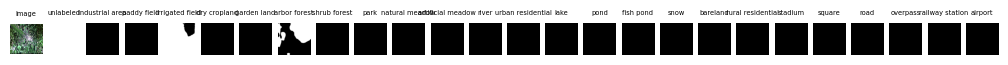

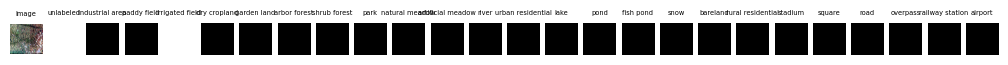

In [ ]:
model_path = "./data/five_billion_pixels/checkpoint.pth.tar"
labels = ["unlabeled","industrial area","paddy field","irrigated field","dry cropland","garden land","arbor forest","shrub forest","park","natural meadow","artificial meadow","river","urban residential","lake","pond","fish pond","snow","bareland","rural residential","stadium","square","road","overpass","railway station","airport"]
transform = ResizeToTensor()
model.load_model(model_path)
plt.rcParams.update({'font.size': 4})
csv_file = "./data/five_billion_pixels/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/five_billion_pixels/' + test_list[0])
image = image[:,:,1:4]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/five_billion_pixels/' + test_list[1])
image = image[:,:,1:4]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/five_billion_pixels/' + test_list[10])
image = image[:,:,1:4]
fig = model.predict_masks(image, labels, transform)